In [ ]:
# Install OpenNeuro downloader tools and Nibabel for NIfTI processing
!npm install -g openneuro-cli
!pip install -q nibabel tensorflow matplotlib pillow

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇npm warn EBADENGINE Unsupported engine {
npm warn EBADENGINE   package: 'elastic-apm-node@3.12.1',
npm warn EBADENGINE   required: { node: '^8.6.0 || 10 || 12 || 13 || 14' },
npm warn EBADENGINE   current: { node: 'v20.19.0', npm: '10.8.2' }
npm warn EBADENGINE }
⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏npm warn deprecated async-cache@1.1.0: No longer maintained. Use [lru-cache](http://npm.im/lru-cache) version 7.6 or higher, and provide an asynchronous `fetchMethod` option.
⠏⠋⠙⠹⠸⠼⠴npm warn deprecated glob@7.2.3: Old versions of glob are not supported, and contain widely publicized security vulnerabilities, which have been fixed in the current version. Please update. Support for old versions may be purchased (at exorbitant rates) by contacting i@izs.m

In [ ]:
import os
import glob
import nibabel as nib
import numpy as np
from PIL import Image

# 1. Clear directories to ensure a fresh, clean start
!rm -rf ds000228 mri_slices openneuro_raw
os.makedirs("mri_slices", exist_ok=True)

print("Cloning the git structure (this only grabs tracking pointers)...")
# Clone just the directory tree layout from your provided link
!git clone --depth 1 https://github.com/OpenNeuroDatasets/ds000228.git

# 2. Locate the anatomical file structures
pointer_files = glob.glob("ds000228/sub-*/anat/*.nii.gz")
print(f"Total available subject folders found: {len(pointer_files)}")

# Target limit setup
MAX_SLICES = 100
slice_count = 0

print(f"\nBeginning download sequence. Targeting exactly {MAX_SLICES} slices...")

for idx, pointer_path in enumerate(pointer_files):
    if slice_count >= MAX_SLICES:
        break

    filename = os.path.basename(pointer_path)
    subject_id = pointer_path.split('/')[1]

    print(f"Downloading raw T1 volume for {subject_id} (Currently at {slice_count}/{MAX_SLICES} slices)...")

    # Direct fetch mapping bypassing Git LFS local restriction
    download_url = f"https://openneuro.org/crn/datasets/ds000228/files/{subject_id}:anat:{filename}"
    local_nii = f"raw_{subject_id}.nii.gz"

    # Curl down the single actual binary file
    !curl -s -L -o {local_nii} "{download_url}"

    try:
        # Load the 3D grid
        img = nib.load(local_nii)
        data = img.get_fdata()

        # Grab a stack of center structural slices
        mid_idx = data.shape[2] // 2
        for s in range(mid_idx - 10, mid_idx + 10):
            if slice_count >= MAX_SLICES:
                break

            slice_data = data[:, :, s]

            # Skip empty dead regions
            if np.max(slice_data) - np.min(slice_data) == 0:
                continue

            # Normalize voxel values to standard 8-bit image scale (0-255)
            slice_norm = ((slice_data - np.min(slice_data)) / (np.max(slice_data) - np.min(slice_data)) * 255).astype(np.uint8)

            # Align orientation to upright view
            img_2d = Image.fromarray(slice_norm).rotate(90)

            # Save final data slice
            img_2d.save(f"mri_slices/slice_{slice_count}.png")
            slice_count += 1

    except Exception as e:
        print(f" Skipping file for {subject_id} due to format reading error: {e}")

    # Crucial step: immediately erase the heavy raw file from Colab storage
    if os.path.exists(local_nii):
        os.remove(local_nii)

print(f"\n Target met! 'mri_slices' directory now contains exactly {slice_count} images.")

Cloning the git structure (this only grabs tracking pointers)...
Cloning into 'ds000228'...
remote: Enumerating objects: 2689, done.
remote: Counting objects: 100% (2689/2689), done.
remote: Compressing objects: 100% (2080/2080), done.
remote: Total 2689 (delta 609), reused 2531 (delta 609), pack-reused 0 (from 0)
Receiving objects: 100% (2689/2689), 7.28 MiB | 12.79 MiB/s, done.
Resolving deltas: 100% (609/609), done.
Total available subject folders found: 155

Beginning download sequence. Targeting exactly 100 slices...

 Target met! 'mri_slices' directory now contains exactly 100 images.


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
import glob

# Parameters perfectly scaled for 100 images
BATCH_SIZE = 10
IMG_SIZE = 64

def preprocess_slice(path):
    image = tf.io.read_file(path)
    # Decode as 1-channel grayscale image
    image = tf.image.decode_png(image, channels=1)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    # Standard GAN normalization scale to map values between [-1, 1]
    image = (image - 127.5) / 127.5
    return image

# Fetch the paths of your 100 images and initialize the tf.data buffer
slice_paths = glob.glob("mri_slices/*.png")
train_dataset = tf.data.Dataset.from_tensor_slices(slice_paths)
train_dataset = train_dataset.map(preprocess_slice).shuffle(len(slice_paths)).batch(BATCH_SIZE)

print("TensorFlow data pipeline built successfully!")

TensorFlow data pipeline built successfully!


In [ ]:
def build_generator():
    return tf.keras.Sequential([
        layers.Dense(4 * 4 * 256, input_shape=(100,)),
        layers.Reshape((4, 4, 256)),
        layers.Conv2DTranspose(128, (5,5), strides=(2,2), padding='same', activation='relu'), # 8x8
        layers.Conv2DTranspose(64, (5,5), strides=(2,2), padding='same', activation='relu'),  # 16x16
        layers.Conv2DTranspose(32, (5,5), strides=(2,2), padding='same', activation='relu'),  # 32x32
        layers.Conv2DTranspose(1, (5,5), strides=(2,2), padding='same', activation='tanh')     # 64x64x1
    ])

def build_discriminator():
    return tf.keras.Sequential([
        layers.Conv2D(64, (5,5), strides=(2,2), padding='same', input_shape=[64, 64, 1], activation=layers.LeakyReLU(0.2)),
        layers.Dropout(0.3),
        layers.Conv2D(128, (5,5), strides=(2,2), padding='same', activation=layers.LeakyReLU(0.2)),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1) # Output raw logits
    ])

generator = build_generator()
discriminator = build_discriminator()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    return cross_entropy(tf.ones_like(real_output), real_output) + cross_entropy(tf.zeros_like(fake_output), fake_output)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

gen_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
disc_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, 100])
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)
        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        g_loss = generator_loss(fake_output)
        d_loss = discriminator_loss(real_output, fake_output)

    generator.optimizer.apply_gradients(zip(gen_tape.gradient(g_loss, generator.trainable_variables), generator.trainable_variables))
    discriminator.optimizer.apply_gradients(zip(disc_tape.gradient(d_loss, discriminator.trainable_variables), discriminator.trainable_variables))
    return g_loss, d_loss

# Explicitly bind the optimizers to the models
generator.optimizer = gen_optimizer
discriminator.optimizer = disc_optimizer

In [ ]:
EPOCHS = 100
print("Beginning GAN execution on OpenNeuro slices...")

for epoch in range(EPOCHS):
    for image_batch in train_dataset:
        gl, dl = train_step(image_batch)

    # Print progress report every 20 epochs
    if (epoch + 1) % 20 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Generator Loss: {gl:.4f} | Discriminator Loss: {dl:.4f}")

Beginning GAN execution on OpenNeuro slices...
Epoch 1/100 | Generator Loss: 0.6162 | Discriminator Loss: 0.8031
Epoch 20/100 | Generator Loss: 1.2381 | Discriminator Loss: 0.8298
Epoch 40/100 | Generator Loss: 0.9357 | Discriminator Loss: 1.0277
Epoch 60/100 | Generator Loss: 0.8112 | Discriminator Loss: 1.3501
Epoch 80/100 | Generator Loss: 1.0798 | Discriminator Loss: 1.0199
Epoch 100/100 | Generator Loss: 0.7873 | Discriminator Loss: 1.1446


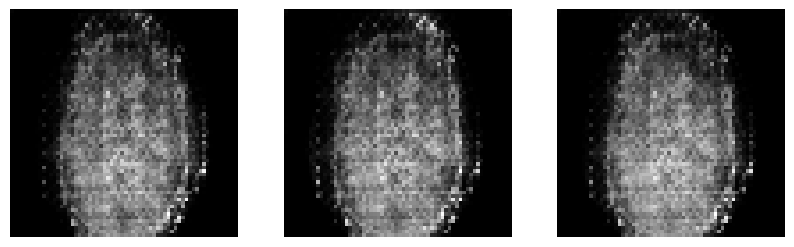

Synthetic MRI dataset generation complete! Your output files are visible in the sidebar folder.


In [ ]:
import matplotlib.pyplot as plt

num_samples = 3
random_noise = tf.random.normal([num_samples, 100])
predictions = generator(random_noise, training=False)

fig = plt.figure(figsize=(10, 5))
for i in range(predictions.shape[0]):
    plt.subplot(1, num_samples, i+1)
    # De-normalize back from [-1, 1] scale to [0, 1] scale for visualization
    img = (predictions[i, :, :, 0] * 127.5 + 127.5) / 255.0
    plt.imshow(img, cmap='gray')
    plt.axis('off')

    os.makedirs("output", exist_ok=True)

    # Save the synthetic PNG out to your workspace panel
    tf.keras.utils.save_img(f"output/synthetic_openneuro_mri_{i+1}.png", predictions[i])

plt.show()
print("Synthetic MRI dataset generation complete! Your output files are visible in the sidebar folder.")